# 2) Bibliographic Data

This notebook inspects the SCOPE Systems and retrieves statistics about authors and journals.

**Important:** Notebooks must be executed in order. You're expected to run notebooks 0 and 1 first.

In [1]:
import csv
import os
import sys
from collections import Counter

import numpy as np
import scope

sys.path.insert(0, os.path.abspath('..'))
from Bibliography.manuscript_search import get_biblio_info, get_complex_formula, get_ligands_formula

import matplotlib.pyplot as plt

## User Configuration

In [ ]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                    # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/"  # Update with your path 
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy" # Update with your path
save_figures  = True

# Figures Path
if save_figures: figures_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Manuscript/figures/"       # Update with your path
else:            figures_path = None 

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path  = analysis_path + "Outputs/"

# Checks Scope Version
expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# This folders are required, together with the system-dedicated folders inside
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"Manuscript Figures: {figures_path}")

SCOPE version:      0.9.6
Data directory:     /Users/sergivela/Documents/SCOPE/Database_SCO/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/
Manuscript Figures: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/


## Loads Systems

### All Unique Systems

In [3]:
unique_csv_path     = outputs_path + "unique_systems.csv"

unique_systems = []
with open(unique_csv_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        sys = scope.load_binary(f"{data_path}/{row['path']}")
        sys.set_paths_from_environment(env)
        unique_systems.append(sys)

print("Unique Systems:", len(unique_systems))

Unique Systems: 602


## Analysis of Database

### Authors

In [4]:
# Extracts Authors from the .cif files of the HS and LS reference cells
only_last = True
HS_aut = []
LS_aut = []
for sys in unique_systems:
    found, sou = sys.find_source("ref_hs_cell")
    if found:
        if only_last: 
            HS_aut.append(sou.cif.authors[-1])
            print(sys.refcode_wo_digits, "from:", sou.cif.authors, 'took', sou.cif.authors[-1])
        else:
            for d in sou.cif.authors:
                a = d.strip("[").strip("]").replace("'", "").replace(" ", "").split(",")
                for au in a:
                    HS_aut.append(au)      
    else:
        print("No source found for ref_hs_cell in system: ", sys.name)
    found, sou = sys.find_source("ref_ls_cell")
    if found:
        if only_last: 
            LS_aut.append(sou.cif.authors[-1])
            print(sys.refcode_wo_digits, "from:", sou.cif.authors, 'took', sou.cif.authors[-1])
        else:
            for d in sou.cif.authors:
                a = d.strip("[").strip("]").replace("'", "").replace(" ", "").split(",")
                for au in a:
                    LS_aut.append(au)  
    else:
        print("No source found for ref_ls_cell in system: ", sys.name)

ABITEM from: ['Rong-Jia Wei', 'Jun Tao', 'Rong-Bin Huang', 'Lan-Sun Zheng'] took Lan-Sun Zheng
ABITEM from: ['Rong-Jia Wei', 'Jun Tao', 'Rong-Bin Huang', 'Lan-Sun Zheng'] took Lan-Sun Zheng
ACAHUJ from: ['J.R.Thompson', 'R.J.Archer', 'C.S.Hawes', 'A.Ferguson', 'A.Wattiaux', 'C.Mathoniere', 'R.Clerac', 'P.E.Kruger'] took P.E.Kruger
ACAHUJ from: ['J.R.Thompson', 'R.J.Archer', 'C.S.Hawes', 'A.Ferguson', 'A.Wattiaux', 'C.Mathoniere', 'R.Clerac', 'P.E.Kruger'] took P.E.Kruger
ADAQUU from: ['H.Hagiwara', 'T.Masuda', 'T.Ohno', 'M.Suzuki', 'T.Udagawa', 'K.Murai'] took K.Murai
ADAQUU from: ['H.Hagiwara', 'T.Masuda', 'T.Ohno', 'M.Suzuki', 'T.Udagawa', 'K.Murai'] took K.Murai
ADAREF from: ['H.Hagiwara', 'T.Masuda', 'T.Ohno', 'M.Suzuki', 'T.Udagawa', 'K.Murai'] took K.Murai
ADAREF from: ['H.Hagiwara', 'T.Masuda', 'T.Ohno', 'M.Suzuki', 'T.Udagawa', 'K.Murai'] took K.Murai
ADEJOK from: ['J.England', 'C.C.Scarborough', 'T.Weyhermuller', 'S.Sproules', 'K.Wieghardt'] took K.Wieghardt
ADEJOK from: ['J.E

In [5]:
count = Counter(HS_aut)
HS_xs = []
HS_ys = []
for c in count.most_common():
    if c[1] >= 4:
        HS_xs.append(c[0])
        HS_ys.append(c[1])

count = Counter(LS_aut)
LS_xs = []
LS_ys = []
for c in count.most_common():
    if c[1] >= 4:
        LS_xs.append(c[0])
        LS_ys.append(c[1])

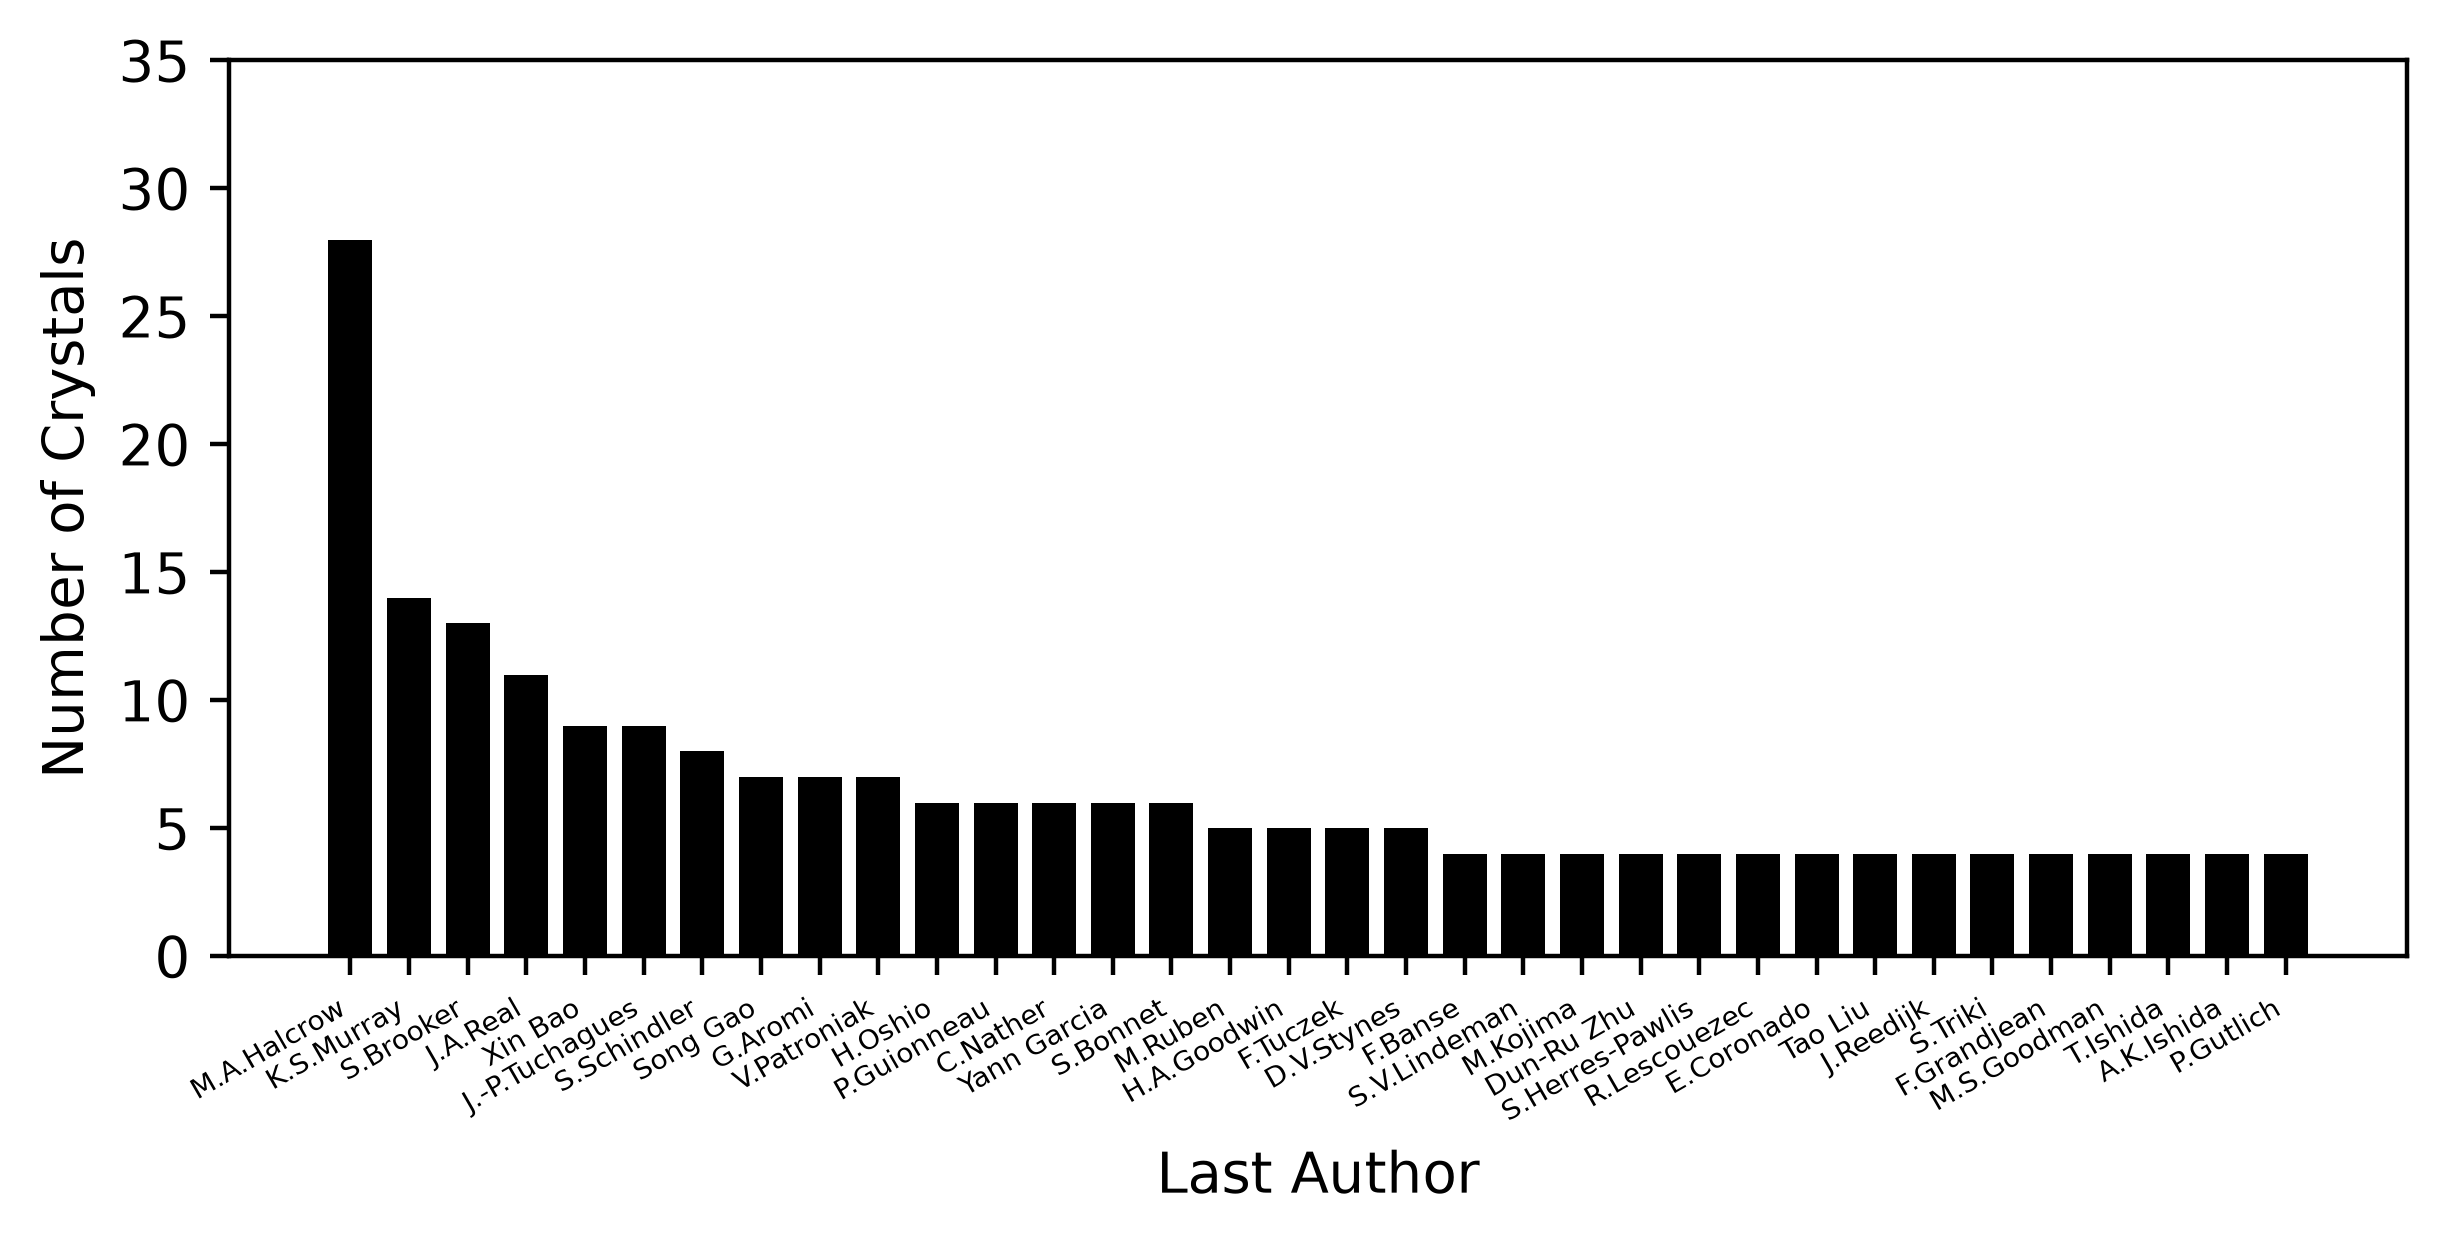

In [6]:
fig, ax = plt.subplots(frameon=False, figsize=[6, 3], dpi=400, constrained_layout=True)
#ax = fig.add_axes([0,0,1,1])
#ax = beautify_ax(ax)
HS_xpos = np.arange(len(HS_xs))
ax.bar(HS_xpos, HS_ys, color = 'black', width = 0.75)
ax.set_ylabel('Number of Crystals')
ax.set_xlabel('Last Author')
ax.set_xticks(HS_xpos, HS_xs)
plt.xticks(rotation=30, ha='right',fontsize=5)
ax.set_yticks(np.arange(0, 40, 5))
fig.savefig(figures_path + "Authors_HS.png", dpi=400)

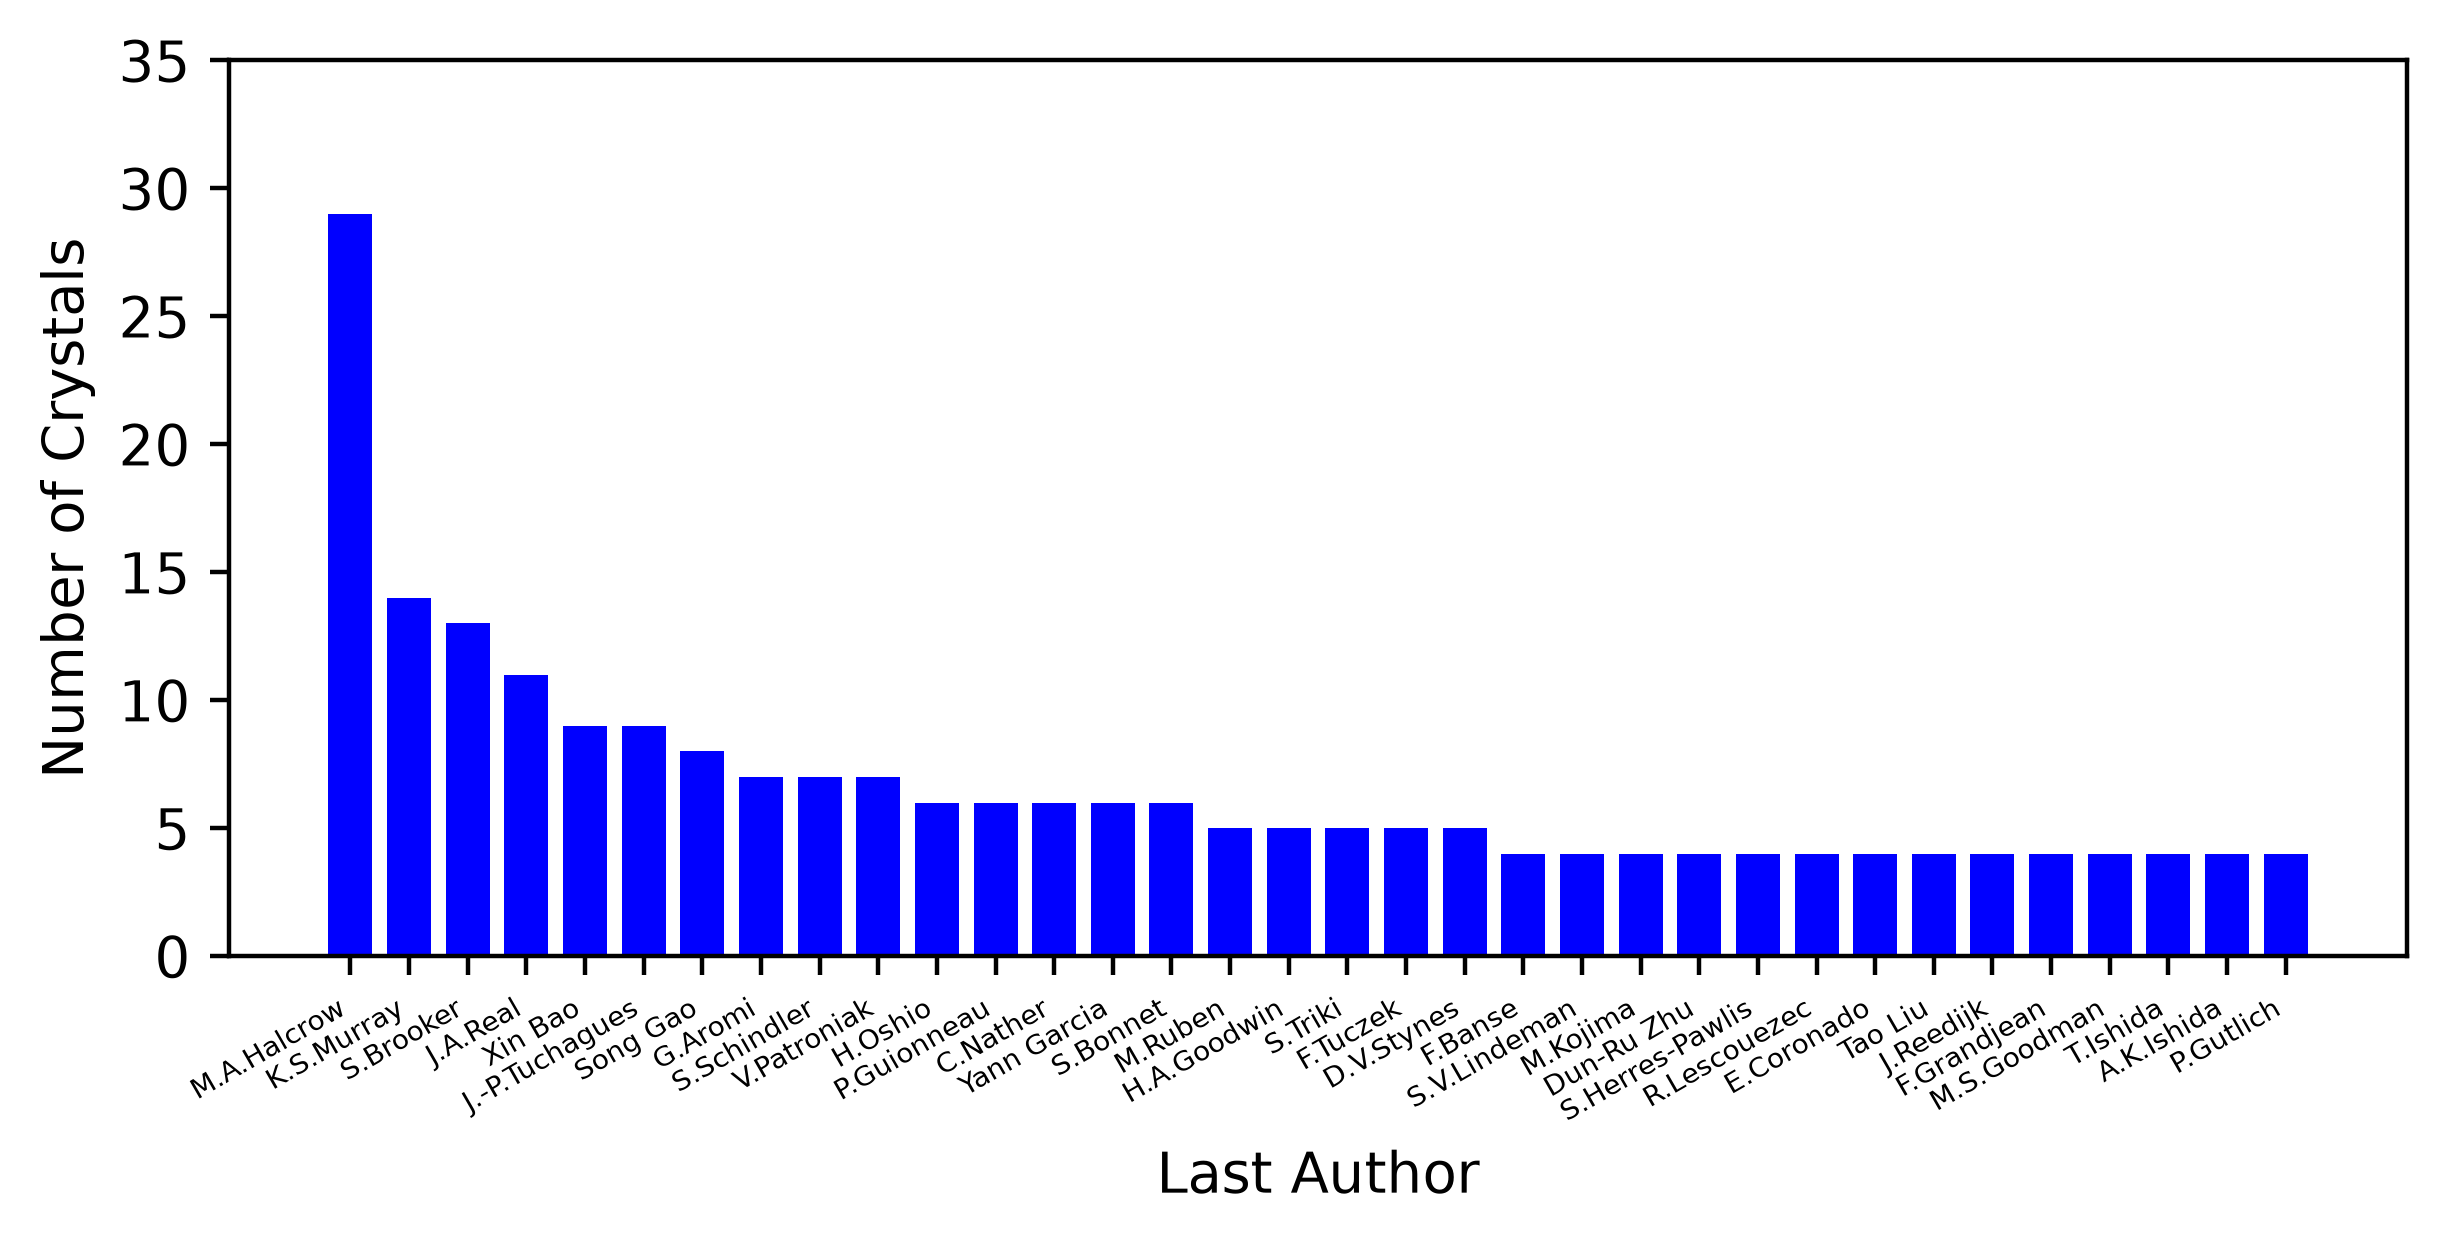

In [7]:
fig, ax = plt.subplots(frameon=False, figsize=[6, 3], dpi=400, constrained_layout=True)
#ax = fig.add_axes([0,0,1,1])
#ax = beautify_ax(ax)
LS_xpos = np.arange(len(LS_xs))
ax.bar(LS_xpos, LS_ys, color = 'blue', width = 0.75)
ax.set_ylabel('Number of Crystals')
ax.set_xlabel('Last Author')
ax.set_xticks(LS_xpos, LS_xs)
plt.xticks(rotation=30, ha='right',fontsize=5)
ax.set_yticks(np.arange(0, 40, 5))
fig.savefig(figures_path + "Authors_LS.png", dpi=400)

### YEAR

In [8]:
year = []
for sys in unique_systems:
    found, sou = sys.find_source("ref_hs_cell")
    if found:
        year.append(sou.cif.journal_year)

In [9]:
year_count = Counter(year)
year_xs = []
year_ys = []
for c in year_count.most_common():
    if c[1] >= 10:
        year_xs.append(c[0])
        year_ys.append(c[1])

In [10]:
year_count

Counter({'2019': 44,
         '2017': 42,
         '2018': 39,
         '2020': 39,
         '2015': 39,
         '2012': 37,
         '2016': 37,
         '2013': 36,
         '2014': 35,
         '2008': 28,
         '2021': 28,
         '2011': 26,
         '2007': 26,
         '2009': 23,
         '2005': 18,
         '2006': 16,
         '2010': 11,
         '2003': 10,
         '2004': 10,
         '1999': 7,
         '1998': 7,
         '2001': 6,
         '1996': 5,
         '1982': 4,
         '2000': 4,
         '1997': 4,
         '1994': 4,
         '1987': 3,
         '2022': 3,
         '2002': 2,
         '1980': 1,
         '1985': 1,
         '1991': 1,
         '1990': 1,
         '1992': 1,
         '1993': 1,
         '1978': 1,
         '1988': 1,
         '1995': 1})

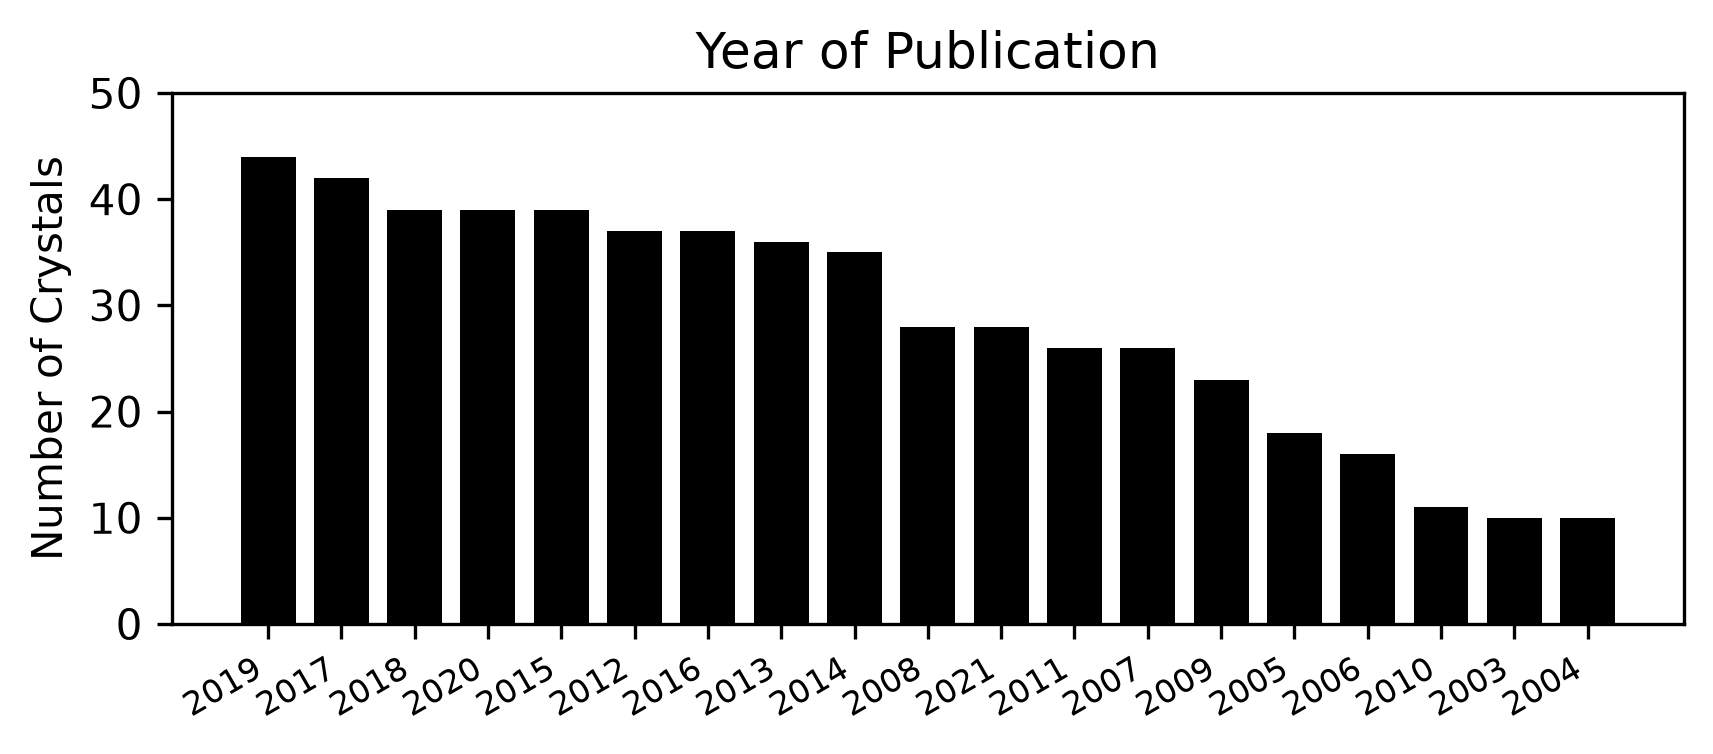

In [11]:
fig, ax = plt.subplots(frameon=False, figsize=[6, 3], dpi=300)
xpos = np.arange(len(year_xs))
ax.bar(xpos, year_ys, color='black', width=0.75)
ax.set_ylabel('Number of Crystals')
ax.set_title('Year of Publication')
ax.set_xticks(xpos, year_xs, rotation=30, ha='right', fontsize=8)
ax.set_yticks(np.arange(0, 51, 10))
fig.subplots_adjust(left=0.14, right=0.98, top=0.86, bottom=0.27)
fig.savefig(figures_path + "Years_HS.png", dpi=300)
plt.show()

### Journal

In [12]:
journal = []
for sys in unique_systems:
    found, sou = sys.find_source("ref_hs_cell")
    if found:
        if sou.cif.journal_name == "CSD Communication(Private Communication)": 
            journal.append("CSD Communication")
        else:
            journal.append(sou.cif.journal_name)

journal_count = Counter(journal)
journal_xs = []
journal_ys = []
for c in journal_count.most_common():
    if c[1] >= 10:
        journal_xs.append(c[0])
        journal_ys.append(c[1])

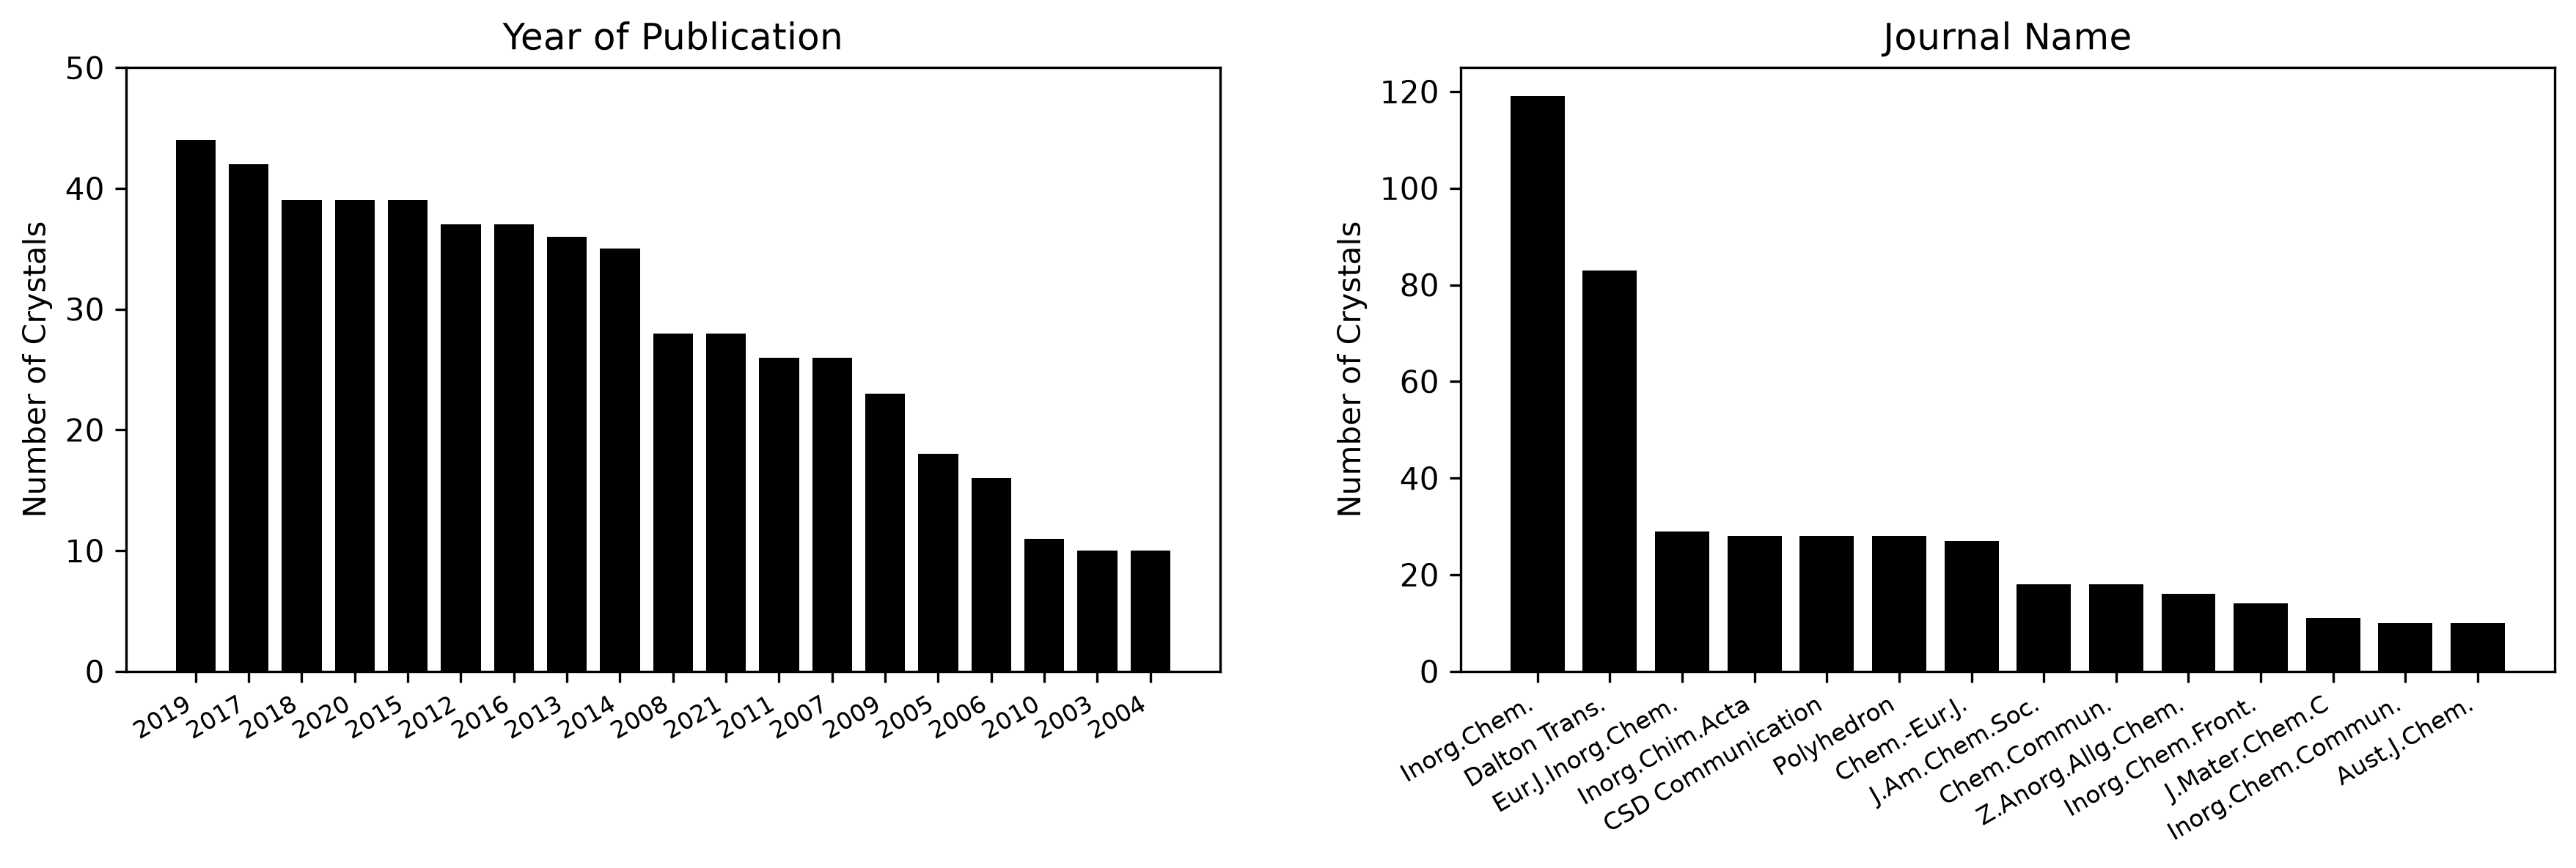

In [13]:
fig, axs = plt.subplots(1, 2, figsize=[12, 4.5], dpi=300)

xpos = np.arange(len(year_xs))
axs[0].bar(xpos, year_ys, color='black', width=0.75)
axs[0].set_ylabel('Number of Crystals')
axs[0].set_title('Year of Publication')
axs[0].set_xticks(xpos, year_xs, rotation=30, ha='right', fontsize=8)
axs[0].set_yticks(np.arange(0, 51, 10))

xpos = np.arange(len(journal_xs))
axs[1].bar(xpos, journal_ys, color='black', width=0.75)
axs[1].set_ylabel('Number of Crystals')
axs[1].set_title('Journal Name')
axs[1].set_xticks(xpos, journal_xs, rotation=30, ha='right', fontsize=8)
axs[1].set_yticks(np.arange(0, 131, 20))

fig.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.27, wspace=0.22)
fig.savefig(figures_path + "Years_Journals_HS.png", dpi=300, facecolor='white', transparent=False)
plt.show()

## Manuscript URL and DOI

Below, we use the functions in Bibliography/manuscript_search.py, to query the Crossref API using System's Data.

### Main Loop

In [14]:
bibliography_csv_path = outputs_path + "unique_bibliographic_data.csv"
bibliography_rows = []
for sys in unique_systems:
    refcode = sys.refcode_wo_digits
    found1, sou_hs = sys.find_source('ref_hs_cell')
    found2, sou_ls = sys.find_source('ref_ls_cell')
    if found1 and found2:
        hs_data = get_biblio_info(sou_hs)
        hs_data.update({"refcode": refcode})
        hs_data.update({"spin_state": "hs"})
        hs_data.update({"mol_formulae": get_complex_formula(sou_hs)}) 
        hs_data.update({"lig_formulae": get_ligands_formula(sou_hs)}) 
        hs_data.update({"diff_temp": sou_hs.cif.diff_temp}) 
        hs_data.update({"sym_group": sou_hs.cif.sym_group}) 
        bibliography_rows.append(hs_data)

        ls_data = get_biblio_info(sou_ls)
        ls_data.update({"refcode": refcode})
        ls_data.update({"spin_state": "ls"})
        ls_data.update({"mol_formulae": get_complex_formula(sou_ls)}) 
        ls_data.update({"lig_formulae": get_ligands_formula(sou_ls)}) 
        ls_data.update({"diff_temp": sou_ls.cif.diff_temp}) 
        ls_data.update({"sym_group": sou_ls.cif.sym_group}) 
        bibliography_rows.append(ls_data)

with open(bibliography_csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["refcode", "spin_state", "authors", "year", "journal", "doi", "url", "mol_formulae", "lig_formulae", "diff_temp", "sym_group"], extrasaction="ignore")
    writer.writeheader()
    writer.writerows(bibliography_rows)

print(f"Wrote {len(bibliography_rows)} rows to {bibliography_csv_path}")

DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Requests
DOI search failed: HTTP Error 429: Too Many Re

## Debug Bibliographic Data

Here, you can debug a specific System's query

In [15]:
for sys in unique_systems:
    if sys.refcode == 'AFANEB02':
        found, sou = sys.find_source('ref_hs_cell')
        hs_data = get_biblio_info(sou, score_threshold=0, crossref_rows=5, debug=1)


crossref_journal_name: 'Chem.-Eur.J.' -> 'Chemistry - A European Journal'
first_cif_author: 'V.A.Money'
Crossref DOI search
  journal_name: 'Chem.-Eur.J.'
  query_journal: 'Chemistry - A European Journal'
  journal_year: '2007'
  journal_volume: '13'
  journal_page: '5503'
  first_author: 'V.A.Money'
  query: 'Chemistry - A European Journal 2007 13 5503 V.A.Money'
  url: https://api.crossref.org/works?query.bibliographic=Chemistry+-+A+European+Journal+2007+13+5503+V.A.Money&rows=5
DOI search failed: HTTP Error 429: Too Many Requests


In [16]:
hs_data['match']

In [17]:
hs_data['query']

''

In [18]:
sou.cif

---------------------------------------------------
                   SCOPE .Cif file                 
---------------------------------------------------
 Name                  = AFANEB02.cif
 Path                  = /Users/sergivela/Documents/SCOPE/Database_SCO/Data/1-Sources/AFANEB02/Original/AFANEB02.cif
 Symmetry Group        = C 2/c
 Symmetry Operations   = ['x,y,z', '1/2+x,1/2+y,z', '-x,y,1/2-z', '1/2-x,1/2+y,1/2-z', '-x,-y,-z', '-1/2-x,-1/2-y,-z', 'x,-y,-1/2+z', '-1/2+x,-1/2-y,-1/2+z']
 Diffraction Temp      = 200.0
 Authors               = ['V.A.Money', 'C.Carbonera', 'J.Elhaik', 'M.A.Halcrow', 'J.A.K.Howard', 'J.-F.Letard']
 Year of Publication   = 2007
 Journal Name          = Chem.-Eur.J.
 Journal Volume        = 13
 Journal Page          = 5503
 Has Associated Cell   = YES